# $\textcolor{limegreen}{\text{IARA: Forecast Tutorial}}$

In [122]:
import os
from pathlib import Path
import iara

# Run from this tutorial's folder: the yaml files and tutorial_output/ are relative to it
os.chdir(Path(iara.__file__).parents[2] / "examples" / "tutorial_forecast")
print("Working directory:", os.getcwd())

Working directory: /Users/joaoferri/codes/iara/examples/tutorial_forecast


## $\textcolor{yellow}{\text{Part 1: Simulating Galaxies}}$

The purpose of IARA is to forecast/measure astrophysical parameters from the cross-correlations of galaxies and gravitational-wave events.

The first step of the process is to simulate galaxy catalogs in a fiducial cosmology. For this, we'll run part1.yaml, which runs only the "compute_matter_cls" and "simulate_galaxies" modules of the code.

Have a look at part1.yaml (inside inputs folder) with a text editor. There, you will find all parameters needed to run these first two modules in a completely idealized scenario (galaxies following a Smail distribution). When you're ready, run the cell below.

In [138]:
#!iara --run inputs/part1.yaml

# If you want to run in parallel, run this instead:

!mpirun -np 4 iara --run inputs/part1.yaml

python(21686) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


/Users/joaoferri/codes/iara/src/iara/main.py:62: UserWarning: nside may be too large for resolution of Gls (lmax_gls = 54). Increase lmax.
  compute_gls(params, monopole=False)
Simulating galaxies...
Simulating galaxies...
  0%|          | 0/1250 [00:00<?, ?it/s]Computing matter Cls...
class: <CAMBparams>
 WantCls = True
 WantTransfer = False
 WantScalars = True
 WantTensors = False
 WantVectors = False
 WantDerivedParameters = True
 Want_cl_2D_array = True
 Want_CMB = True
 Want_CMB_lensing = True
 DoLensing = True
 NonLinear = NonLinear_both
 Transfer: <TransferParams>
   high_precision = False
   accurate_massive_neutrinos = False
   kmax = 0.9
   k_per_logint = 0
   PK_num_redshifts = 1
   PK_redshifts = [0.0]
 want_zstar = False
 want_zdrag = False
 min_l = 2
 max_l = 2500
 max_l_tensor = 600
 lens_output_margin = 200
 max_eta_k = 6250.0
 max_eta_k_tensor = 1200.0
 ombh2 = 0.02237
 omch2 = 0.12
 omk = 0.0
 omnuh2 = 0.0006448993754203254
 H0 = 67.36
 TCMB = 2.7255
 YHe = 0.24565603

Below we will plot the first galaxy simulation for a given redshift bin.

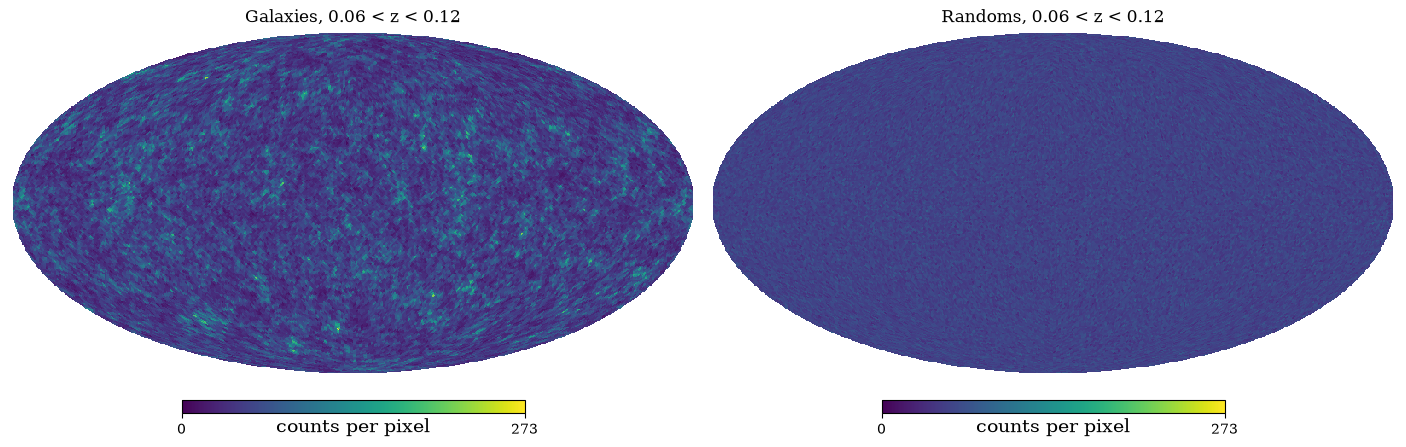

In [124]:
import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
import yaml

with open("inputs/part1.yaml") as f:
    params = yaml.safe_load(f)

gdir = params["storage"] + params["gdir"]
zb = np.array(params["bin_edges"])

# First simulation: galaxy counts and randoms, shape (Nbins, Npix)
gal = np.load(f"{gdir}/gal_count_map1.npy")
rand = np.load(f"{gdir}_rand/gal_count_map1.npy")

i = 1 #redshift bin
vmax = max(gal[i].max(), rand[i].max())

fig = plt.figure(figsize=(14, 5))
hp.mollview(gal[i], sub=(1, 2, 1), fig=fig.number, min=0, max=vmax, unit="counts per pixel",
            title=f"Galaxies, {zb[i]:.2f} < z < {zb[i+1]:.2f}")
hp.mollview(rand[i], sub=(1, 2, 2), fig=fig.number, min=0, max=vmax, unit="counts per pixel",
            title=f"Randoms, {zb[i]:.2f} < z < {zb[i+1]:.2f}")
plt.show()

## $\textcolor{yellow}{\text{Part 2: Simulating GW Maps}}$

The second step of the process is to simulate GW catalogs on top of the galaxy mocks. For this, we'll run part2.yaml, which runs only the "simulate_gws" module of the code.

Have a look at part2.yaml. There, you will find all parameters needed to run this module in a forecast scenario (GWs following a forecast from a detector configuration). In this example, we are using the same LVK O5 forecast from the example folder.

In [139]:
#!iara --run inputs/part2.yaml

# If you want to run in parallel, run this instead:

!mpirun -np 4 iara --run inputs/part2.yaml

python(29175) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


/Users/joaoferri/miniforge3/envs/iara/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(
No lensing magnification
Loaded 377 events from ./inputs/lvkO5.txt
Simulating 334 GW events inside the redshift bins (43 detections fall outside them)
Number of thick bins: 2
  0%|          | 0/1250 [00:00<?, ?it/s]No lensing magnification
Loaded 377 events from ./inputs/lvkO5.txt
Simulating 334 GW events inside the redshift bins (43 detections fall outside them)
Number of thick bins: 2
  0%|          | 0/1250 [00:00<?, ?it/s]No lensing magnification
Loaded 377 events from ./inputs/lvkO5.txt
Simulating 334 GW events inside the redshift bins (43 detections fall outside them)
Number of thick bins:

Below we plot the GW mocks + Randoms (i.e. GW events put on top of galaxy randoms). We also plot the spatial PDF that incorporates the spatial sensitivity of a given detector configuration.

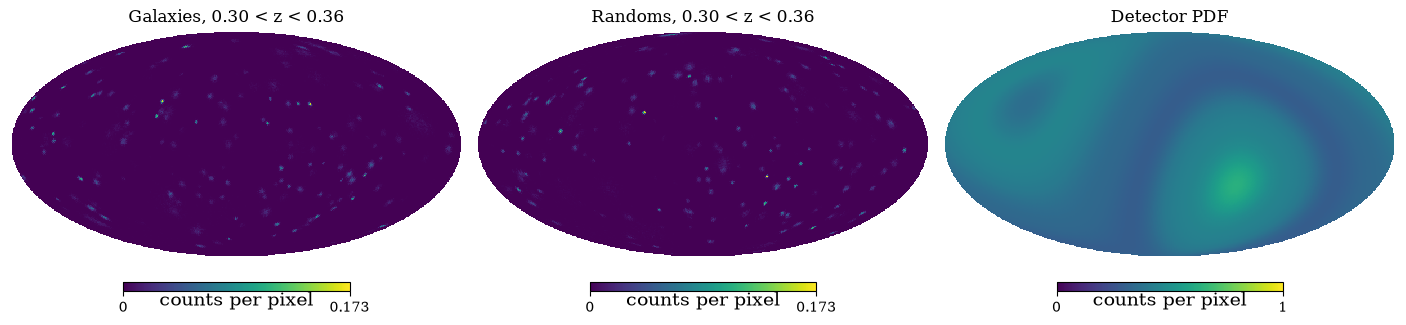

In [126]:
import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
import yaml

with open("inputs/part2.yaml") as f:
    params = yaml.safe_load(f)

bdir = params["storage"] + params["bdir"]
zb = np.array(params["bin_edges"])

# First simulation: galaxy counts and randoms, shape (Nbins, Npix)
gw = np.load(f"{bdir}/bbh_count_map1.npy")
gw_rand = np.load(f"{bdir}_rand/bbh_count_map1.npy")
spatial_pdf = np.loadtxt(f"{bdir}/hist_maps_smooth.txt")
i = 5 #redshift bin
vmax = max(gw[i].max(), gw_rand[i].max())

fig = plt.figure(figsize=(14, 5))
hp.mollview(gw[i], sub=(1, 3, 1), fig=fig.number, min=0, max=vmax, unit="counts per pixel",
            title=f"Galaxies, {zb[i]:.2f} < z < {zb[i+1]:.2f}")
hp.mollview(gw_rand[i], sub=(1, 3, 2), fig=fig.number, min=0, max=vmax, unit="counts per pixel",
            title=f"Randoms, {zb[i]:.2f} < z < {zb[i+1]:.2f}")
hp.mollview(spatial_pdf[0], sub=(1, 3, 3), fig=fig.number, min=0, max=1, unit="counts per pixel",
            title=f"Detector PDF")
plt.show()

## $\textcolor{yellow}{\text{Part 3: Cross-correlations}}$

The third step of the process is to compute the cross-correlations of the Galaxy-GW pairs. For this, we'll run part3.yaml, which runs only the "compute_cls" module of the code.

Have a look at part3.yaml. There, you will find all parameters needed to run this module.

In [140]:
#!iara --run inputs/part3.yaml

# If you want to run in parallel, run this instead:

!mpirun -np 4 iara --run inputs/part3.yaml

python(29302) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Using simple galactic cut mask
redshift_independent_mask: False
Computed coupling matrices
  0%|          | 0/1250 [00:00<?, ?it/s]Using simple galactic cut mask
redshift_independent_mask: False
Computed coupling matrices
  0%|          | 0/1250 [00:00<?, ?it/s]Using simple galactic cut mask
redshift_independent_mask: False
Computed coupling matrices
  0%|          | 0/1250 [00:00<?, ?it/s]Using simple galactic cut mask
redshift_independent_mask: False
Computed coupling matrices
 14%|█▍        | 172/1250 [01:17<07:15,  2.47it/s]computing alms
0.3535580635070801   seconds
computing cls
0.03819108009338379   seconds
inverting pseudo-cls
saving cls of simulation 1
computing alms
0.4191312789916992   seconds
computing cls
0.013962268829345703   seconds
inverting pseudo-cls
saving cls of simulation 5
computing alms
0.33111095428466797   seconds
computing cls
0.013855934143066406   seconds
inverting pseudo-cls
saving cls of simulation 9
computing alms
0.34464573860168457   seconds
computing 

Below are two plots: (Left) the average Cls (galaxy-auto, gw-auto, galaxy-gw) across a single redshift bin (i,i). (Right) The average galaxy-gw cross-correlation summed across multipoles, as a function of $D_L$ and $z$.

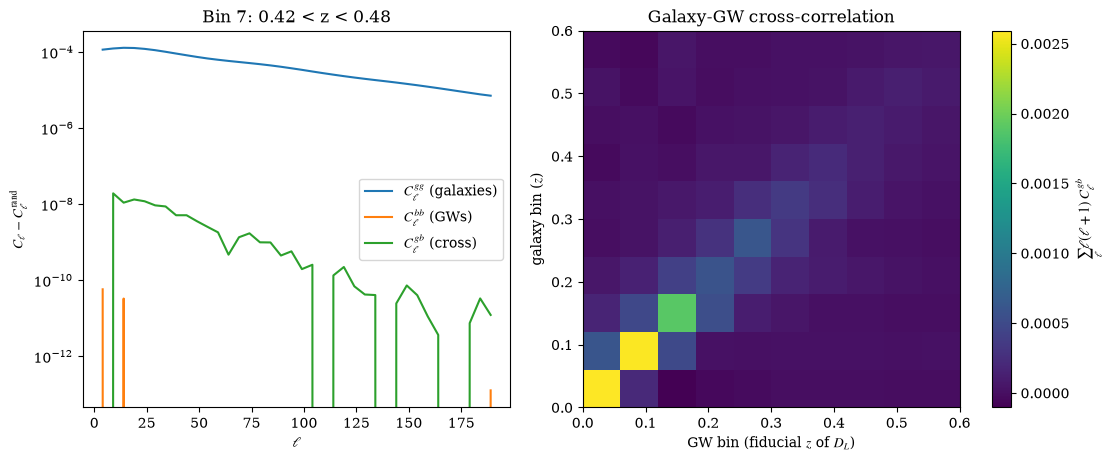

In [153]:
import numpy as np
import matplotlib.pyplot as plt
import yaml

with open("inputs/part3.yaml") as f:
    params = yaml.safe_load(f)

cls_dir = params["storage"] + params["cls_dir"]
zb = np.array(params["bin_edges"])

# Average Cls from simulations minus those of the randoms: Cl_gg, Cl_bb, Cl_gb
cl_gg = np.load(f"{cls_dir}/Cl_gg_mean.npy") - np.load(f"{cls_dir}_rand/Cl_gg_mean.npy")
cl_bb = np.load(f"{cls_dir}/Cl_bb_mean.npy") - np.load(f"{cls_dir}_rand/Cl_bb_mean.npy")
cl_gb = np.load(f"{cls_dir}/Cl_gb_mean.npy") - np.load(f"{cls_dir}_rand/Cl_gb_mean.npy")

# Centres of the multipole bands (bands of size bs from ell = 2)
bs = params["bs"]
lvec = 2 + bs*np.arange(cl_gg.shape[0]) + (bs - 1)/2
weight = lvec*(lvec + 1)

i = 7  # redshift bin

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")

# Left: auto and cross spectra of bin i (negative values are not shown on the log scale)
ax1.semilogy(lvec, cl_gg[:, i, i], label=r"$C_\ell^{gg}$ (galaxies)")
ax1.semilogy(lvec, cl_bb[:, i, i], label=r"$C_\ell^{bb}$ (GWs)")
ax1.semilogy(lvec, cl_gb[:, i, i], label=r"$C_\ell^{gb}$ (cross)")
ax1.set_xlabel(r"$\ell$")
ax1.set_ylabel(r"$C_\ell - C_\ell^{\rm rand}$")
ax1.set_title(f"Bin {i}: {zb[i]:.2f} < z < {zb[i+1]:.2f}")
ax1.legend()

# Right: cross spectra of all pairs of bins, summed over multipoles
img2 = ax2.pcolormesh(zb, zb, np.sum(cl_gb*weight[:, None, None], axis=0))
fig.colorbar(img2, ax=ax2, label=r"$\sum_\ell \ell(\ell+1)\,C_\ell^{gb}$")
ax2.set_xlabel(r"GW bin (fiducial $z$ of $D_L$)")
ax2.set_ylabel(r"galaxy bin ($z$)")
ax2.set_title("Galaxy-GW cross-correlation")
ax2.set_aspect("equal")
plt.show()

You will notice that, for a small number of simulations, the average is dominated by sampling noise. For the redshift and monopole bins of interest, it is necessary a number of $O(10^4)$ simulations for the average cross-correlations to converge. Performing the next step (inference) with an un-converged average over-estimates the constraining power, as it treats statistical noise as signal. Keep in mind that such high number of simulations may take tens to hundreds of gigabites of storage. When you're ready, you can swap the number of simulations on all 3 scripts with the cell below; then re-run steps 1-3.

In [137]:
import re
import yaml
import shutil

N_sim = 5000  # number of simulations used in parts 1-3 . 1000-5000 simulations recomended for this example.

for part in ["inputs/part1.yaml", "inputs/part2.yaml", "inputs/part3.yaml", "inputs/part4.yaml"]:
    with open(part) as f:
        text = f.read()
    # Replace only the value of N_sim, keeping the comments of the file
    text, n = re.subn(r'^("N_sim"\s*:\s*)[^#\n]*?(\s*(#.*)?)$', rf'\g<1>{N_sim}\g<2>', text, flags=re.M)
    if n != 1:
        raise ValueError(f"Expected one N_sim line in {part}, found {n}")
    with open(part, "w") as f:
        f.write(text)
    print(f"{part}: N_sim = {yaml.safe_load(text)['N_sim']}")

# Cleaning the tutorial output.
shutil.rmtree("tutorial_output", ignore_errors=True)  # remove outputs made with the previous N_sim

inputs/part1.yaml: N_sim = 5000
inputs/part2.yaml: N_sim = 5000
inputs/part3.yaml: N_sim = 5000


## $\textcolor{yellow}{\text{Part 4: Parameter Inference}}$

The fourth and final step of the tutorial is the inference of cosmological parameters from the cross-correlations. Here we'll assume that both theory and data input are the average cross-correlations.
Have a look at part4.yaml. There, you will find all parameters needed for the MCMC.

In [141]:
#!iara --run inputs/part4.yaml

# If you want to run in parallel, run this instead:

!mpirun -np 4 iara --run inputs/part4.yaml

python(29577) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Using simple galactic cut mask
Number of galaxies per bin: mean over 1000 simulations in ./tutorial_output/galaxies
Initialized global parameters
Initialized theory
Initialized data
Using avg as data Cls
Loaded Gls
Initialized likelihood with Fisher covariance (f_sky = 0.672)
100%|██████████| 2000/2000 [01:07<00:00, 29.82it/s]
/Users/joaoferri/codes/iara/src/iara/mcmc.py:154: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  g.fig.tight_layout(rect=[0, 0, 1, 0.95])
Number of samples: 15200
Parameter names: ['H0', 'OM']
Ranges: {'H0': (20, 140), 'OM': (0.1, 0.5)}
Fiducial values: {'H0': 67.36, 'OM': 0.3138}
Removed no burn in
Marginalized 1D Best Fits +- 1sigma
H0: 67.859 (+13.083, -15.965)
OM: 0.264 (+0.132, -0.164)


Below is the result of the MCMC. 

Number of samples: 15200
Parameter names: ['H0', 'OM']
Ranges: {'H0': (20, 140), 'OM': (0.1, 0.5)}
Fiducial values: {'H0': 67.36, 'OM': 0.3138}
Removed no burn in


/Users/joaoferri/codes/iara/src/iara/mcmc.py:154: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  g.fig.tight_layout(rect=[0, 0, 1, 0.95])


Marginalized 1D Best Fits +- 1sigma
H0: 67.859 (+13.083, -15.965)
OM: 0.264 (+0.132, -0.164)


<Figure size 900x900 with 0 Axes>

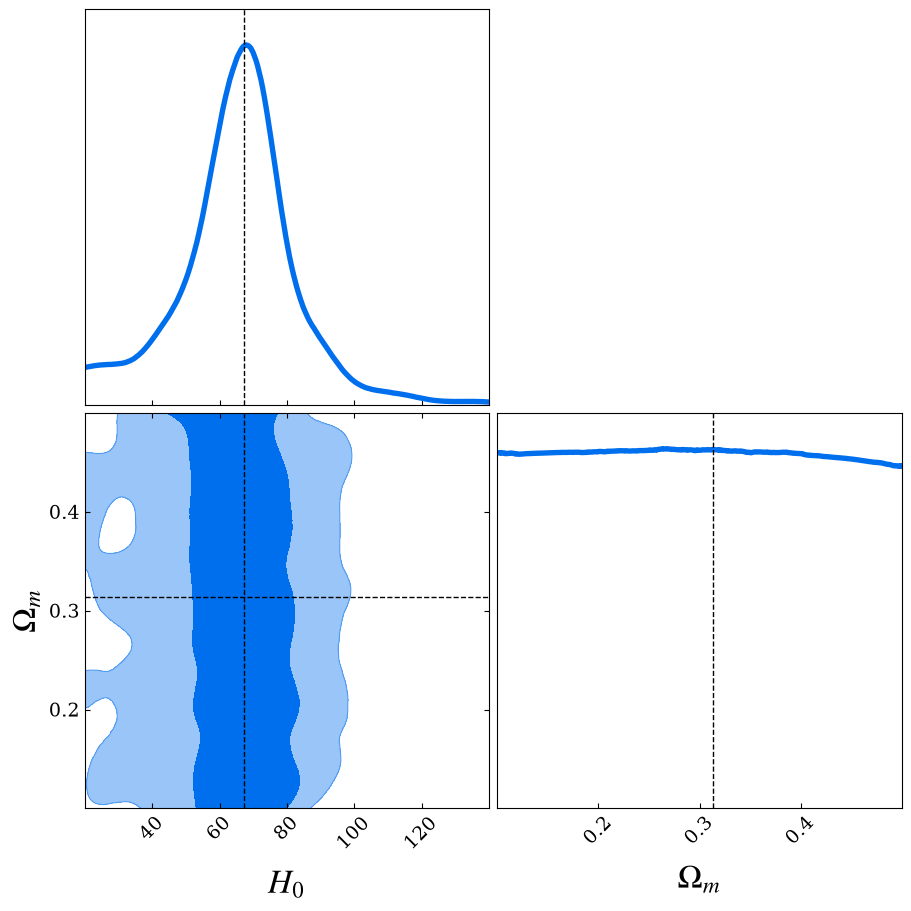

In [142]:
import yaml
import matplotlib.pyplot as plt
from iara.mcmc import plot_contours

with open("inputs/part4.yaml") as f:
    params = yaml.safe_load(f)

plot_contours(params, param_labels=[r"H_0", r"\Omega_m"])
plt.show()

A good robustness check to your results is plotting the contribution of each bandpower to the likelihood. Since GW events have limited spatial resolution, we can expect that the bandpower contribution to $\chi^2$ decays as $\ell$ increases. For the LVK O5 case, most events have resolution $\sim\ell\leq150$, so a robust inference should show little contribution at higher ells. 

A flat curve must raise a yellow flag: the cross-correlation average may still not be converged, so the likelihood is dominated by noise and parameter uncertainty may be underestimated. To aid with convergence, increase the number of simulations, join redshift bins together with a 'coarse_bin' parameter (at the cost of probably losing constraining power due to poor radial resolution) or, as a cheap solution, tune 'cut_bins' to a range where the cross-correlation signal is stronger.

Each forecast will have a different trade-off between number of redshift bins and simulations. Increasing the number of bins requires more simulations. Reduce it too much (generally to a width bigger than the most radially constrained events) and you lose constraining power. It is trial and error.

Using simple galactic cut mask
Number of galaxies per bin: mean over 1000 simulations in ./tutorial_output/galaxies
Using avg as data Cls
Loaded Gls


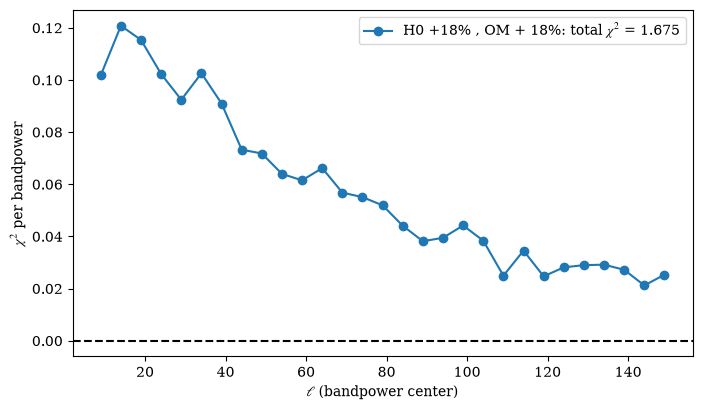

In [143]:
import yaml
import matplotlib.pyplot as plt
import iara.likelihood as lk

with open("inputs/part4.yaml") as f:
    params = yaml.safe_load(f)

# Likelihood with the Fisher covariance, as in iara.mcmc.mcmc
par = lk.global_parameters(params)
theory = lk.cl_theory(par)
data = lk.cl_data(par)
like = lk.likelihood(par, lk.inverse_covariance(par, theory), theory, data)

ell = par.lbvec[par.lb_idx_min:par.lb_idx_max]  # centres of the bandpowers used

perc = 18 # perc% shift on fiducial cosmology from data

# Parameters --% away from the fiducial values

shifts = {
    f"H0 +{perc}% , OM + {perc}%": dict(h0= (1+perc/100)*par.H0, om=(1+perc/100)*par.OM),
}

fig, ax = plt.subplots(figsize=(8, 4.5))
for label, p in shifts.items():
    chi2_ell = like.chi2(p["h0"], p["om"], par.bgw, par.w0, par.wa)  # chi2 of each bandpower
    ax.plot(ell, chi2_ell, "o-", label=f"{label}: total $\\chi^2$ = {chi2_ell.sum():.3f}")
ax.axhline(0,ls='--',color='black')
ax.set_xlabel(r"$\ell$ (bandpower center)")
ax.set_ylabel(r"$\chi^2$ per bandpower")
ax.legend()
plt.show()

In the cell below, you can see the impact of 'coarse_bin' and 'cut_bins' in the cross-correlation used for the likelihood

Using simple galactic cut mask
Number of galaxies per bin: mean over 5000 simulations in ./tutorial_output/galaxies
Using simple galactic cut mask
Number of galaxies per bin: mean over 5000 simulations in ./tutorial_output/galaxies


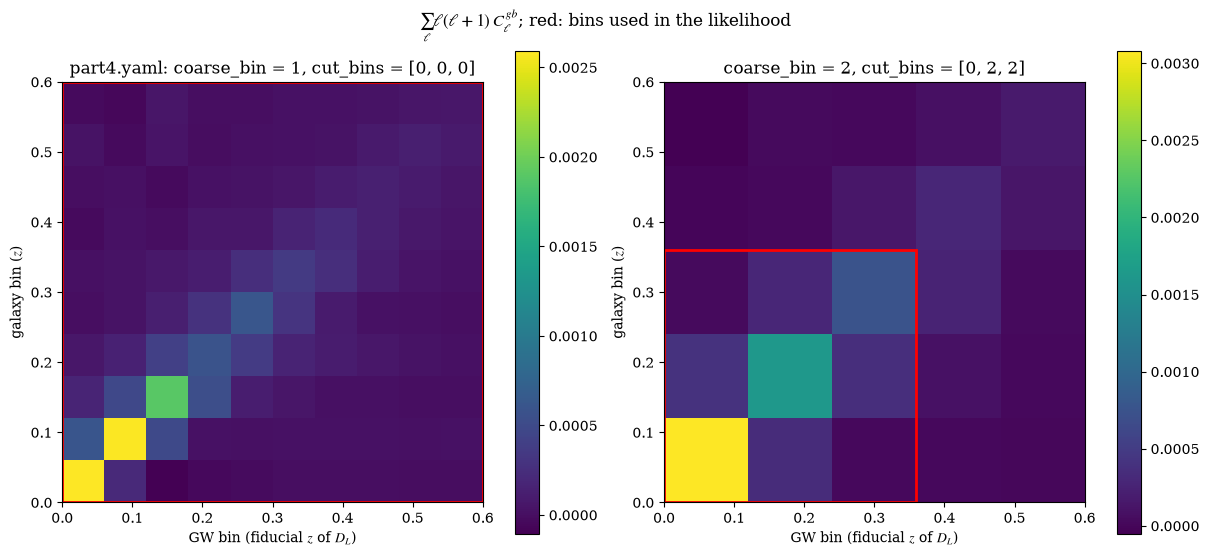

In [145]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import yaml
import iara.likelihood as lk

# Choose the likelihood binning to visualise
coarse_bin = 2        # number of simulation bins joined in each likelihood bin
cut_bins = [0, 2, 2]  # likelihood bins removed: [low distance, high distance, high redshift]

with open("inputs/part4.yaml") as f:
    params = yaml.safe_load(f)

# Likelihood binning of part4.yaml, and the one chosen above
par_orig = lk.global_parameters(params)
par_new = lk.global_parameters({**params, "coarse_bin": coarse_bin, "cut_bins": cut_bins})

# Average Cl_gb minus randoms (as in the likelihood), in the simulation bins
cls_dir = params["storage"] + params["cls_theory_dir"]
cl_gb = np.load(f"{cls_dir}/Cl_gb_mean.npy") - np.load(f"{cls_dir}_rand/Cl_gb_mean.npy")
weight = par_orig.lbvec*(par_orig.lbvec + 1)

def summed_cl(par, cl):
    """Sum over multipoles of l(l+1) Cl_gb in the likelihood bins of par (galaxy bins x GW bins)."""
    cl_bins = par.rebinning_Cl(cl, type="zDfid")  # joins coarse_bin simulation bins (nothing for coarse_bin = 1)
    return np.sum(cl_bins*weight[:cl_bins.shape[0], None, None], axis=0)

def draw(ax, par, title):
    edges = par.gal_zs2  # bin edges in redshift (GW bins: the fiducial distance of these redshifts)
    img = ax.pcolormesh(edges, edges, summed_cl(par, cl_gb), shading="flat")
    plt.colorbar(img, ax=ax)

    # Bins kept in the likelihood: galaxy bins below the z cut, GW bins between the distance cuts
    lower, upper, zcut = par.cuts
    nb = par.gal_bins
    x0, x1 = edges[lower], edges[nb - upper]
    y0, y1 = edges[0], edges[nb - zcut]
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="red", lw=2))

    ax.set_xlabel(r"GW bin (fiducial $z$ of $D_L$)")
    ax.set_ylabel(r"galaxy bin ($z$)")
    ax.set_title(title)
    ax.set_aspect("equal")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5), layout="constrained")
draw(ax1, par_orig, f"part4.yaml: coarse_bin = {par_orig.coarse_bin}, cut_bins = {par_orig.cuts}")
draw(ax2, par_new, f"coarse_bin = {coarse_bin}, cut_bins = {cut_bins}")
fig.suptitle(r"$\sum_\ell \ell(\ell+1)\, C_\ell^{gb}$; red: bins used in the likelihood")
plt.show()

# When you're confortable with all steps, take a look at the lvkO5_forecast folder in the examples. It contains all steps 1-4 in a single script file.